**1.Importing libraries**

In [30]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.feature_extraction.text import CountVectorizer

**CountVectorizer** to convert text data into numerical features using word counts.
**MultinomialNB** The Naive Bayes classifier for multinomial data and is ideal for text classification.

**2.Loading the Dataset**

In [3]:
data = pd.read_csv("Data/synthetic_text_data.csv")
data.head()

,text,label
0,Artificial intelligence is advancing in health...,Technology
1,Football fans are excited about the upcoming W...,Sports
2,New policies regarding climate change have spa...,Politics
3,The latest blockbuster movie has shattered box...,Entertainment
4,Quantum computing promises to revolutionize in...,Technology


In [4]:
X = data['text']
y = data['label']

**3.Splitting the Data**

In [5]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2, random_state = 42)

**4.Text Preprocessing: Converting Text to Numeric Features**

In [14]:
# CountVectorizer(): Converts the raw text into a matrix of word counts.
vectorizer = CountVectorizer()
# fit_transform(): Learns the vocabulary from the training data and transforms the text into vector.
X_train_vectorized = vectorizer.fit_transform(X_train)
# transform(): Applies the learned vocabulary from the training data to the test data.
X_test_vectorized = vectorizer.transform(X_test)

**5. Training the Naive Bayes Classifier**

In [17]:
model = MultinomialNB()
model.fit(X_train_vectorized, y_train)

MultinomialNB()

**6. Making Predictions**

In [18]:
y_pred = model.predict(X_test_vectorized)

**7. Evaluating the Model**

Accuracy:88.23529411764706%


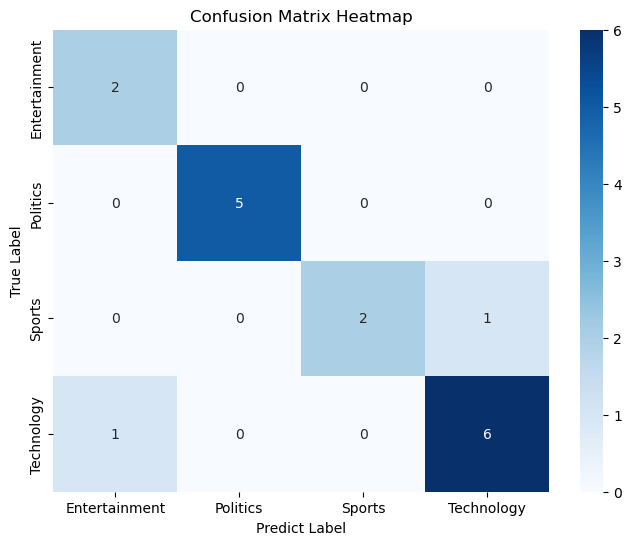

In [37]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f"Accuracy:{accuracy*100}%")
class_labels = np.unique(y_test)

plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',xticklabels = class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predict Label')
plt.ylabel('True Label')
plt.show()

Looking at the confusion matrix heatmap we can see the model made correct predictions for Sports (2), Technology (5), Politics (2) and Entertainment (6). Heatmap shows these values with darker colors representing correct predictions. However there were some misclassifications.

**8. Prediction on Unseen Data**

In [39]:
user_input = ("I love artificial intelligence and machine learning")

user_input_vectorized = vectorizer.transform([user_input])
predicted_label = model.predict(user_input_vectorized)
print(f"The input text belongs to the '{predicted_label[0]}' category.")

The input text belongs to the 'Technology' category.


Here we can see our model is working fine and can predict on unseen data accurately. Naive Bayes is a useful model for text classification tasks especially when the dataset is large and the features (words) are relatively independent.